# Diamond Price Prediction
**Question:** How much of a diamond's price can we predict from its size, cut, color, and clarity, and which of those matter most?

**Workflow:** load → explore → clean → transform → baseline → models → evaluate → interpret

This is a *regression* project: the target (price) is a number, not a category.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

## 2. Load and inspect

In [2]:
df = sns.load_dataset("diamonds")
print(df.shape)
df.head()

(53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


**Observation:** about 54,000 diamonds with no missing values. But `x`, `y`, `z` (the dimensions in mm) have a minimum of 0, which is physically impossible. That's a data quality problem to fix.

## 3. Exploratory data analysis

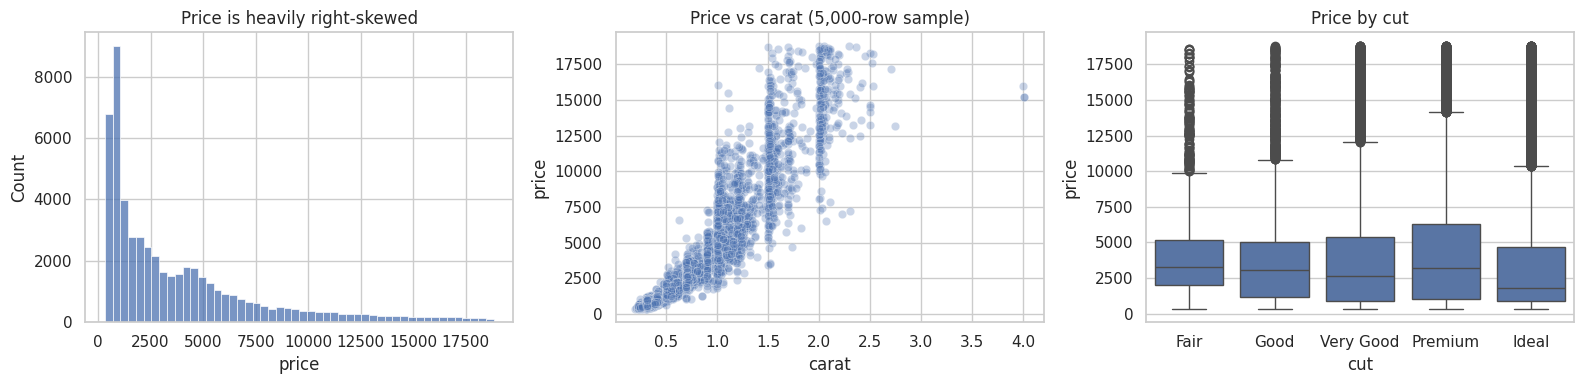

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["price"], bins=50, ax=axes[0])
axes[0].set_title("Price is heavily right-skewed")

sample = df.sample(5000, random_state=42)
sns.scatterplot(data=sample, x="carat", y="price", alpha=0.3, ax=axes[1])
axes[1].set_title("Price vs carat (5,000-row sample)")

sns.boxplot(data=df, x="cut", y="price",
            order=["Fair", "Good", "Very Good", "Premium", "Ideal"], ax=axes[2])
axes[2].set_title("Price by cut")
plt.tight_layout()
plt.show()

**Observations:**
- Price is right-skewed, so a few very expensive diamonds pull the average up.
- Price rises steeply and non-linearly with carat.
- Surprisingly, "Ideal" cut diamonds are *not* the most expensive. Think about why before moving on (hint: what else differs between cuts? check carat by cut).

In [5]:
df.groupby("cut", observed=True)["carat"].mean().sort_values()

,carat
cut,
Ideal,0.702837
Very Good,0.806381
Good,0.849185
Premium,0.891955
Fair,1.046137


## 4. Clean the data

In [6]:
print("Rows with a zero dimension:", ((df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0)).sum())
print("Extreme y or z values:")
print(df[(df["y"] > 20) | (df["z"] > 20)][["carat", "x", "y", "z", "price"]])

Rows with a zero dimension: 20
Extreme y or z values:
       carat     x      y      z  price
24067   2.00  8.09  58.90   8.06  12210
48410   0.51  5.12   5.15  31.80   1970
49189   0.51  5.15  31.80   5.12   2075


In [7]:
clean = df[(df["x"] > 0) & (df["y"] > 0) & (df["z"] > 0)]
clean = clean[(clean["y"] < 20) & (clean["z"] < 20)].copy()
print(f"Removed {len(df) - len(clean)} impossible rows, {len(clean)} remain")

Removed 23 impossible rows, 53917 remain


## 5. Transform and engineer features

In [8]:
# The three quality columns have a natural order, so encode them as ordered numbers.
cut_order     = {"Fair": 1, "Good": 2, "Very Good": 3, "Premium": 4, "Ideal": 5}
color_order   = {"J": 1, "I": 2, "H": 3, "G": 4, "F": 5, "E": 6, "D": 7}          # D is best
clarity_order = {"I1": 1, "SI2": 2, "SI1": 3, "VS2": 4, "VS1": 5, "VVS2": 6, "VVS1": 7, "IF": 8}

clean["cut_n"]     = clean["cut"].astype(str).map(cut_order)
clean["color_n"]   = clean["color"].astype(str).map(color_order)
clean["clarity_n"] = clean["clarity"].astype(str).map(clarity_order)

# Price and carat are skewed and related multiplicatively, so work in log space.
clean["log_carat"] = np.log(clean["carat"])
clean["log_price"] = np.log(clean["price"])

features = ["log_carat", "cut_n", "color_n", "clarity_n", "depth", "table", "x", "y", "z"]
X = clean[features]
y = clean["log_price"]
clean[["log_carat", "log_price"]].corr()

,log_carat,log_price
log_carat,1.000000,0.965921
log_price,0.965921,1.000000


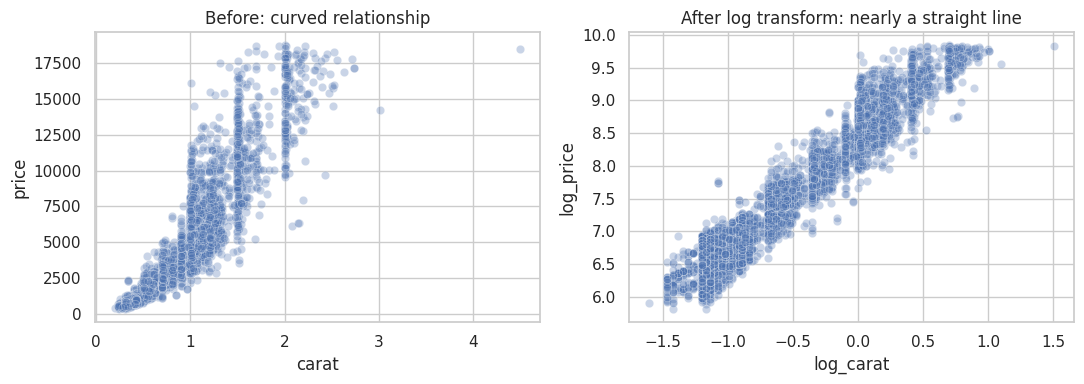

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=clean.sample(5000, random_state=42), x="carat", y="price", alpha=0.3, ax=axes[0])
axes[0].set_title("Before: curved relationship")
sns.scatterplot(data=clean.sample(5000, random_state=42), x="log_carat", y="log_price", alpha=0.3, ax=axes[1])
axes[1].set_title("After log transform: nearly a straight line")
plt.tight_layout()
plt.show()

## 6. Train/test split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

Train: 43133 rows | Test: 10784 rows


## 7. Baseline and models
Models predict log price, so we convert back to dollars with `np.exp()` before measuring error. That way the error is in a unit that means something.

In [11]:
def report(name, log_pred):
    pred = np.exp(log_pred)
    actual = np.exp(y_test)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae = mean_absolute_error(actual, pred)
    r2 = r2_score(actual, pred)
    print(f"{name:<22} RMSE: ${rmse:>8,.0f} | MAE: ${mae:>7,.0f} | R²: {r2:.3f}")
    return pred

# Baseline: always guess the average training price. Any real model must beat this.
baseline = np.full(len(y_test), np.log(np.exp(y_train).mean()))
_ = report("Baseline (mean price)", baseline)

lin = LinearRegression().fit(X_train, y_train)
lin_pred = report("Linear regression", lin.predict(X_test))

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train, y_train)
rf_pred = report("Random forest", rf.predict(X_test))

Baseline (mean price)  RMSE: $   3,970 | MAE: $  3,008 | R²: -0.000
Linear regression      RMSE: $     919 | MAE: $    455 | R²: 0.946
Random forest          RMSE: $     532 | MAE: $    264 | R²: 0.982


## 8. Where does the best model go wrong?

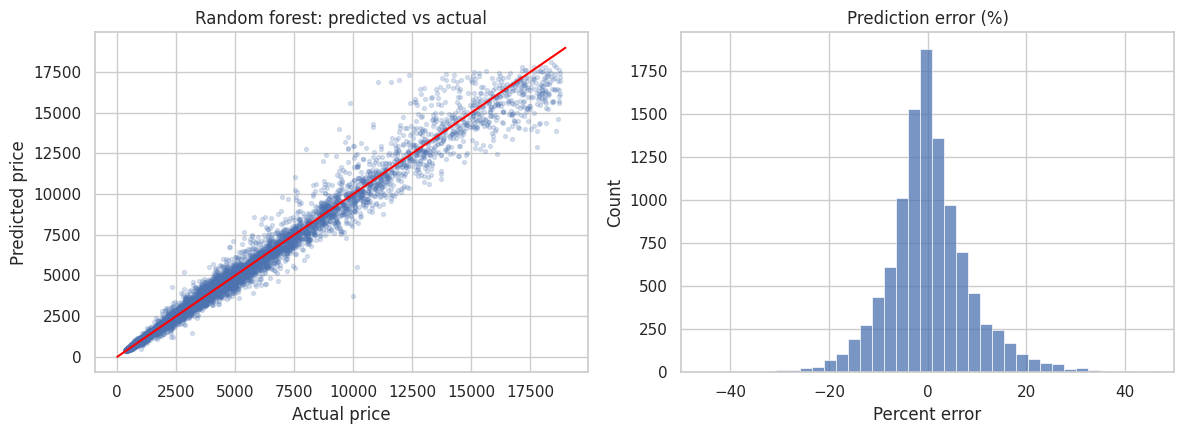

Median absolute % error: 4.4%


In [12]:
actual = np.exp(y_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(actual, rf_pred, alpha=0.2, s=8)
axes[0].plot([0, 19000], [0, 19000], color="red")
axes[0].set_xlabel("Actual price"); axes[0].set_ylabel("Predicted price")
axes[0].set_title("Random forest: predicted vs actual")

pct_error = (rf_pred - actual) / actual * 100
sns.histplot(pct_error, bins=60, ax=axes[1])
axes[1].set_xlim(-50, 50)
axes[1].set_xlabel("Percent error"); axes[1].set_title("Prediction error (%)")
plt.tight_layout()
plt.show()

print(f"Median absolute % error: {pct_error.abs().median():.1f}%")

## 9. Which features matter?

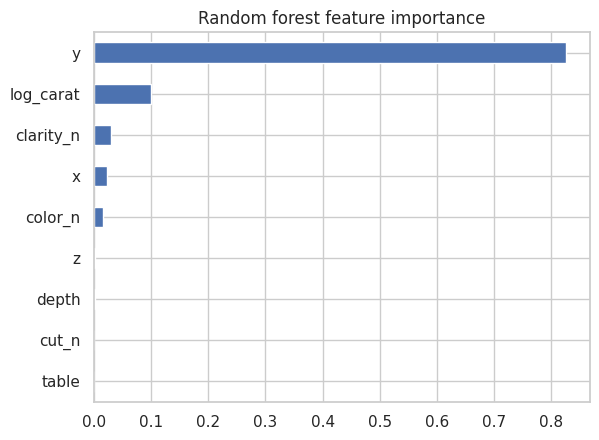

In [13]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", title="Random forest feature importance")
plt.show()

**Note:** `x`, `y`, `z`, and `log_carat` all describe size, so they share the importance between them. That's why carat alone can look less dominant than it really is. This is called *multicollinearity*, and it's worth being able to explain.

## 10. Conclusions
- **Best model and its error:** The random forest, with an RMSE of about $532, MAE of $264 and R² of 0.98 on the held-out 20%. A typical prediction is off by roughly 4.4% (median absolute % error). The mean-price baseline had an RMSE of about $3,970 and linear regression $919, so both beat the baseline, and the forest cut linear regression's error by about 40%.
- **Which features mattered most:** Size dominated. `y` (width) alone carried about 85% of the forest's importance, with `log_carat` at 7% and `x` at 2%. Because x, y, z and carat all measure size, they split the credit among themselves, so the real message is that physical size drives price. Clarity (3%) and color (2%) came next. This fits how diamonds are priced: carat first, then clarity and color.
- **One thing that surprised me:** `cut` barely mattered (about 0.1% importance), and Ideal-cut diamonds had the lowest average price of the five cuts ($3,457). The reason is that Ideal stones are smaller on average (0.70 carat versus 1.05 for Fair), and carat drives price far more than cut. Cut quality only shows up once size is held fixed.
- **Limitations:** The data is one catalog snapshot, so it ignores the date, the seller and market changes. It has no information on fluorescence or certification. The forest was left at default settings, and the very expensive large stones are rare, so errors are likely larger there. The 4.4% median error also hides some larger misses.
- **What I'd try next:** Cross-validation instead of a single split, tuning the forest with GridSearchCV, trying gradient boosting, and dropping redundant size columns (x, y, z) to see whether the importances become easier to read.